In [1]:
# الخلية 1: استيراد المكتبات
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

print("جاهز ✅")
print(f"Pandas: {pd.__version__}")

جاهز ✅
Pandas: 2.3.3


In [2]:
# الخلية 2: تحميل البيانات
# ⚠️ لاحظ: الملف مفصول بفاصلة منقوطة (;) وليس فاصلة عادية
# لو استخدمنا sep الافتراضي (,) سيقرأ كل الصف كعمود واحد

DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"  # ← عدّل حسب مسارك

df = pd.read_csv(DATA_PATH, sep=";")

print("تم التحميل ✅")
print(f"عدد الصفوف: {df.shape[0]}")
print(f"عدد الأعمدة: {df.shape[1]}")

تم التحميل ✅
عدد الصفوف: 7043
عدد الأعمدة: 21


In [3]:
# الخلية 3: أول 5 صفوف — لنرى شكل البيانات الحقيقي
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# الخلية 4: أنواع الأعمدة
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [5]:
# الخلية 5: توزيع Churn
print("القيم المطلقة:")
print(df["Churn"].value_counts())

print("\nالنسب:")
print(df["Churn"].value_counts(normalize=True).round(3))

القيم المطلقة:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

النسب:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [6]:
# الخلية 6: الفحص الدقيق لـ TotalCharges
# isnull() لا يكتشف المسافات البيضاء، لذا نحتاج فحصاً مزدوجاً

print("=" * 60)
print("1) القيم المفقودة (NaN) كما يراها Pandas:")
print("=" * 60)
print(df.isnull().sum())

print("\n" + "=" * 60)
print("2) فحص TotalCharges كرقم (المسافات تصبح NaN):")
print("=" * 60)
total_charges_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing_total = total_charges_numeric.isnull().sum()
print(f"عدد القيم التي لا يمكن تحويلها لرقم: {missing_total}")

print("\n" + "=" * 60)
print("3) هل هذه القيم مرتبطة بعملاء جدد (tenure = 0)؟")
print("=" * 60)
tenure_zero = (df["tenure"] == 0).sum()
print(f"عدد صفوف tenure = 0: {tenure_zero}")

print("\n" + "=" * 60)
print("4) فحص الصفوف التي TotalCharges فيها مفقود:")
print("=" * 60)
missing_rows = df[total_charges_numeric.isnull()]
print(f"عدد الصفوف: {len(missing_rows)}")
print("\nقيم tenure لهذه الصفوف:")
print(missing_rows["tenure"].value_counts())
print("\nقيم MonthlyCharges لهذه الصفوف (أول 5):")
print(missing_rows["MonthlyCharges"].head())

1) القيم المفقودة (NaN) كما يراها Pandas:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

2) فحص TotalCharges كرقم (المسافات تصبح NaN):
عدد القيم التي لا يمكن تحويلها لرقم: 11

3) هل هذه القيم مرتبطة بعملاء جدد (tenure = 0)؟
عدد صفوف tenure = 0: 11

4) فحص الصفوف التي TotalCharges فيها مفقود:
عدد الصفوف: 11

قيم tenure لهذه الصفوف:
tenure
0    11
Name: count, dtype: int64

قيم MonthlyCharges لهذه الصفوف (أول 5):
488     52.55
753     20.25
936     80.85
1082    25.75
1340    56.05
Name: MonthlyCharges, dtype: float64


In [7]:
# الخلية 7: فحص الـ 11 صفاً المفقودة قبل اتخاذ قرار التنظيف
# نريد أن نعرف: هل فيها مغادرون؟ ما توزيع Churn فيها؟

total_charges_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing_mask = total_charges_numeric.isnull()

# نعرض هذه الصفوف بأعمدة مختارة
cols_to_view = ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]
print("الصفوف الـ 11 التي TotalCharges فيها مفقود:")
print(df.loc[missing_mask, cols_to_view].to_string())

print("\n" + "=" * 60)
print("توزيع Churn في هذه الصفوف الـ 11:")
print("=" * 60)
print(df.loc[missing_mask, "Churn"].value_counts())

print("\n" + "=" * 60)
print("مقارنة: توزيع Churn في كل البيانات:")
print("=" * 60)
print(df["Churn"].value_counts(normalize=True).round(3))

الصفوف الـ 11 التي TotalCharges فيها مفقود:
      customerID  tenure  MonthlyCharges TotalCharges  Contract Churn
488   4472-LVYGI       0           52.55               Two year    No
753   3115-CZMZD       0           20.25               Two year    No
936   5709-LVOEQ       0           80.85               Two year    No
1082  4367-NUYAO       0           25.75               Two year    No
1340  1371-DWPAZ       0           56.05               Two year    No
3331  7644-OMVMY       0           19.85               Two year    No
3826  3213-VVOLG       0           25.35               Two year    No
4380  2520-SGTTA       0           20.00               Two year    No
5218  2923-ARZLG       0           19.70               One year    No
6670  4075-WKNIU       0           73.35               Two year    No
6754  2775-SEFEE       0           61.90               Two year    No

توزيع Churn في هذه الصفوف الـ 11:
Churn
No    11
Name: count, dtype: int64

مقارنة: توزيع Churn في كل البيانات:
Chu

In [8]:
# الخلية 8: التعامل مع TotalCharges المفقود
# القرار: نملأ بـ 0 (عميل جديد لم يدفع بعد)
# + نضيف عموداً يشير إلى أن القيمة كانت مفقودة (Missing Indicator)

# 1. نحول TotalCharges إلى رقم (المسافات تصبح NaN)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# 2. ننشئ عموداً يشير إلى القيم المفقودة الأصلية (قبل الملء)
df["TotalCharges_missing"] = df["TotalCharges"].isnull().astype(int)

# 3. نملأ القيم المفقودة بـ 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# 4. التحقق
print("بعد التنظيف:")
print(f"عدد القيم المفقودة في TotalCharges: {df['TotalCharges'].isnull().sum()}")
print(f"نوع TotalCharges: {df['TotalCharges'].dtype}")
print(f"عدد الصفوف التي كانت مفقودة (Missing Indicator = 1): {df['TotalCharges_missing'].sum()}")

print("\n" + "=" * 60)
print("إحصائيات TotalCharges بعد التنظيف:")
print("=" * 60)
print(df["TotalCharges"].describe().round(2))

بعد التنظيف:
عدد القيم المفقودة في TotalCharges: 0
نوع TotalCharges: float64
عدد الصفوف التي كانت مفقودة (Missing Indicator = 1): 11

إحصائيات TotalCharges بعد التنظيف:
count    7043.00
mean     2279.73
std      2266.79
min         0.00
25%       398.55
50%      1394.55
75%      3786.60
max      8684.80
Name: TotalCharges, dtype: float64


C:\Users\hp\AppData\Local\Temp\ipykernel_2468\3247286244.py:19: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df["TotalCharges"], vert=True)


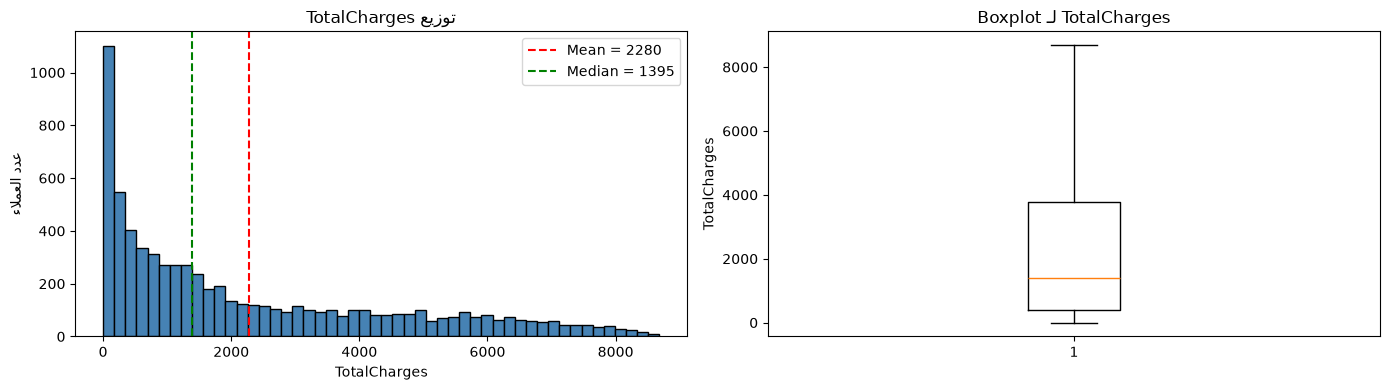

In [9]:
# الخلية 10: رسم توزيع TotalCharges
# لنرى بأعيننا الانحراف الذي اكتشفناه من الإحصائيات

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# الرسم الأول: Histogram
axes[0].hist(df["TotalCharges"], bins=50, color="steelblue", edgecolor="black")
axes[0].axvline(df["TotalCharges"].mean(), color="red", linestyle="--", label=f"Mean = {df['TotalCharges'].mean():.0f}")
axes[0].axvline(df["TotalCharges"].median(), color="green", linestyle="--", label=f"Median = {df['TotalCharges'].median():.0f}")
axes[0].set_title("توزيع TotalCharges")
axes[0].set_xlabel("TotalCharges")
axes[0].set_ylabel("عدد العملاء")
axes[0].legend()

# الرسم الثاني: Boxplot (يكشف القيم الشاذة)
axes[1].boxplot(df["TotalCharges"], vert=True)
axes[1].set_title("Boxplot لـ TotalCharges")
axes[1].set_ylabel("TotalCharges")

plt.tight_layout()
plt.show()

In [10]:
# الخلية 11: تحويلات أساسية قبل EDA
# 1. حذف customerID (معرف فريد لا يفيد النموذج)
# 2. تحويل Churn من Yes/No إلى 1/0 (النموذج لا يفهم نصوصاً)

print("قبل التحويل:")
print(f"  عدد الأعمدة: {df.shape[1]}")
print(f"  قيم Churn: {df['Churn'].unique()}")

# 1. حذف customerID
df = df.drop(columns=["customerID"])

# 2. تحويل Churn إلى 0/1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("\nبعد التحويل:")
print(f"  عدد الأعمدة: {df.shape[1]}")
print(f"  قيم Churn: {df['Churn'].unique()}")
print(f"  نوع Churn: {df['Churn'].dtype}")

print("\n" + "=" * 60)
print("توزيع Churn بعد التحويل:")
print("=" * 60)
print(df["Churn"].value_counts())
print(f"\nنسبة المغادرين: {df['Churn'].mean():.3f}")

قبل التحويل:
  عدد الأعمدة: 22
  قيم Churn: ['No' 'Yes']

بعد التحويل:
  عدد الأعمدة: 21
  قيم Churn: [0 1]
  نوع Churn: int64

توزيع Churn بعد التحويل:
Churn
0    5174
1    1869
Name: count, dtype: int64

نسبة المغادرين: 0.265


Churn حسب نوع العقد:
                عدد العملاء  نسبة المغادرة
Contract                                  
Month-to-month         3875          0.427
One year               1473          0.113
Two year               1695          0.028


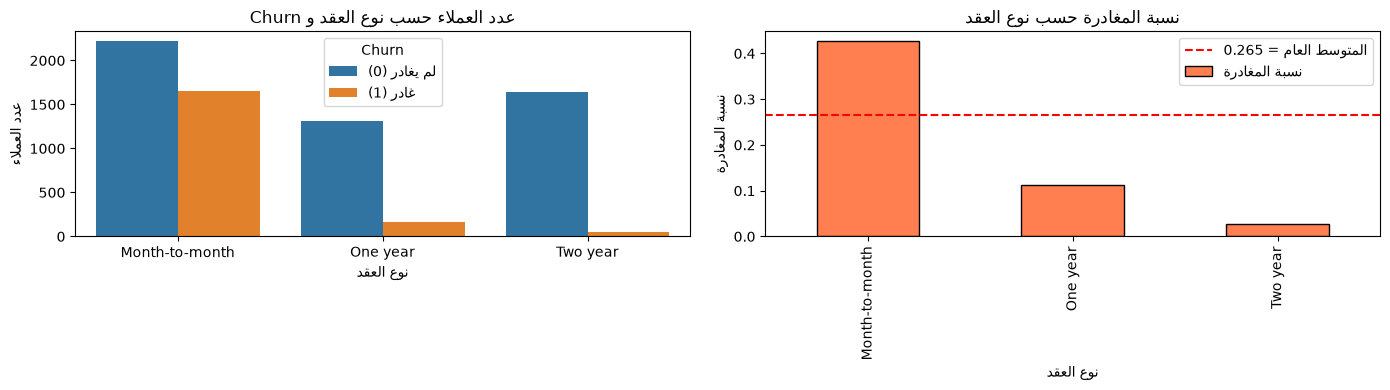

In [11]:
# الخلية 12: Churn حسب نوع العقد (Contract)
# السؤال: هل نوع العقد يؤثر على المغادرة؟

# جدول النسب
churn_by_contract = df.groupby("Contract")["Churn"].agg(["count", "mean"]).round(3)
churn_by_contract.columns = ["عدد العملاء", "نسبة المغادرة"]
print("Churn حسب نوع العقد:")
print(churn_by_contract)

# الرسم
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# الرسم الأول: Countplot
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0])
axes[0].set_title("عدد العملاء حسب نوع العقد و Churn")
axes[0].set_xlabel("نوع العقد")
axes[0].set_ylabel("عدد العملاء")
axes[0].legend(title="Churn", labels=["لم يغادر (0)", "غادر (1)"])

# الرسم الثاني: Barplot للنسب
churn_by_contract["نسبة المغادرة"].plot(kind="bar", ax=axes[1], color="coral", edgecolor="black")
axes[1].set_title("نسبة المغادرة حسب نوع العقد")
axes[1].set_xlabel("نوع العقد")
axes[1].set_ylabel("نسبة المغادرة")
axes[1].axhline(df["Churn"].mean(), color="red", linestyle="--", label=f"المتوسط العام = {df['Churn'].mean():.3f}")
axes[1].legend()

plt.tight_layout()
plt.show()

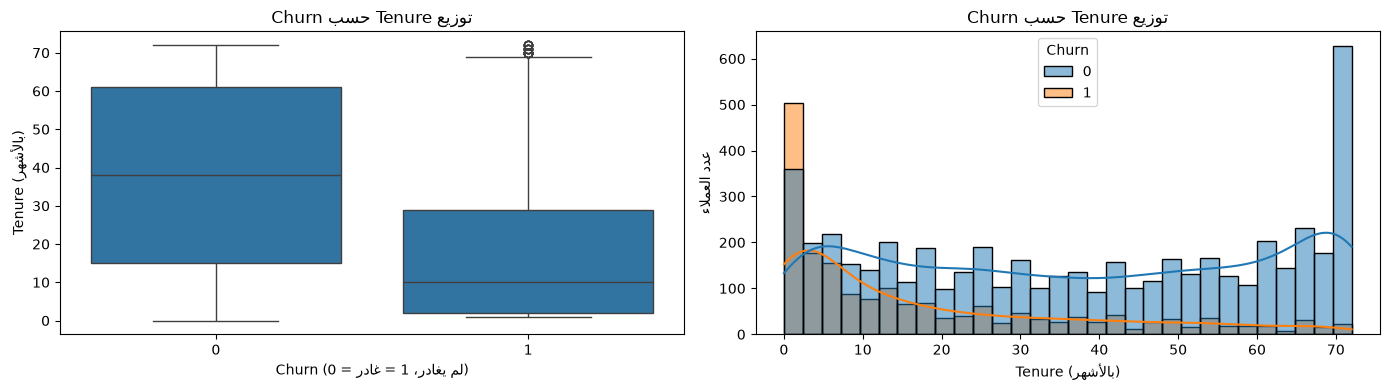

متوسط Tenure حسب Churn:
Churn
0    37.57
1    17.98
Name: tenure, dtype: float64


In [12]:
# الخلية 13: Churn حسب tenure (مدة بقاء العميل)
# السؤال: هل العملاء الجدد يغادرون أكثر من القدامى؟

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# الرسم الأول: Boxplot — tenure حسب Churn
sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("توزيع Tenure حسب Churn")
axes[0].set_xlabel("Churn (0 = لم يغادر، 1 = غادر)")
axes[0].set_ylabel("Tenure (بالأشهر)")

# الرسم الثاني: Histogram — توزيع tenure لكل فئة
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, ax=axes[1])
axes[1].set_title("توزيع Tenure حسب Churn")
axes[1].set_xlabel("Tenure (بالأشهر)")
axes[1].set_ylabel("عدد العملاء")

plt.tight_layout()
plt.show()

# إحصائيات
print("متوسط Tenure حسب Churn:")
print(df.groupby("Churn")["tenure"].mean().round(2))

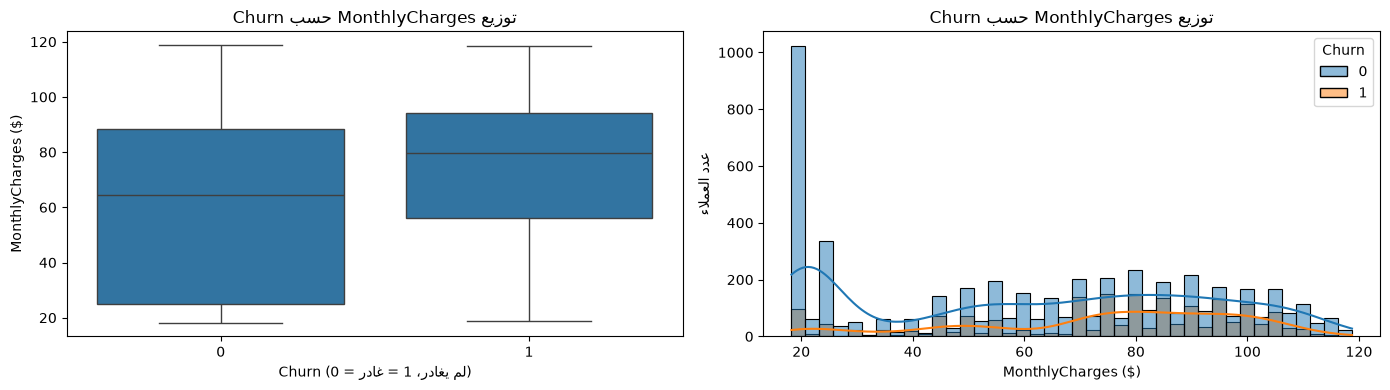

متوسط MonthlyCharges حسب Churn:
Churn
0    61.27
1    74.44
Name: MonthlyCharges, dtype: float64


In [13]:
# الخلية 14: Churn حسب MonthlyCharges (الفاتورة الشهرية)
# السؤال: هل العملاء ذوو الفواتير الأعلى يغادرون أكثر؟

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# الرسم الأول: Boxplot
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[0])
axes[0].set_title("توزيع MonthlyCharges حسب Churn")
axes[0].set_xlabel("Churn (0 = لم يغادر، 1 = غادر)")
axes[0].set_ylabel("MonthlyCharges ($)")

# الرسم الثاني: Histogram
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=40, kde=True, ax=axes[1])
axes[1].set_title("توزيع MonthlyCharges حسب Churn")
axes[1].set_xlabel("MonthlyCharges ($)")
axes[1].set_ylabel("عدد العملاء")

plt.tight_layout()
plt.show()

# إحصائيات
print("متوسط MonthlyCharges حسب Churn:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

Churn حسب نوع الإنترنت:
                 عدد العملاء  نسبة المغادرة
InternetService                            
DSL                     2421          0.190
Fiber optic             3096          0.419
No                      1526          0.074

Churn حسب طريقة الدفع:
                           عدد العملاء  نسبة المغادرة
PaymentMethod                                        
Bank transfer (automatic)         1544          0.167
Credit card (automatic)           1522          0.152
Electronic check                  2365          0.453
Mailed check                      1612          0.191


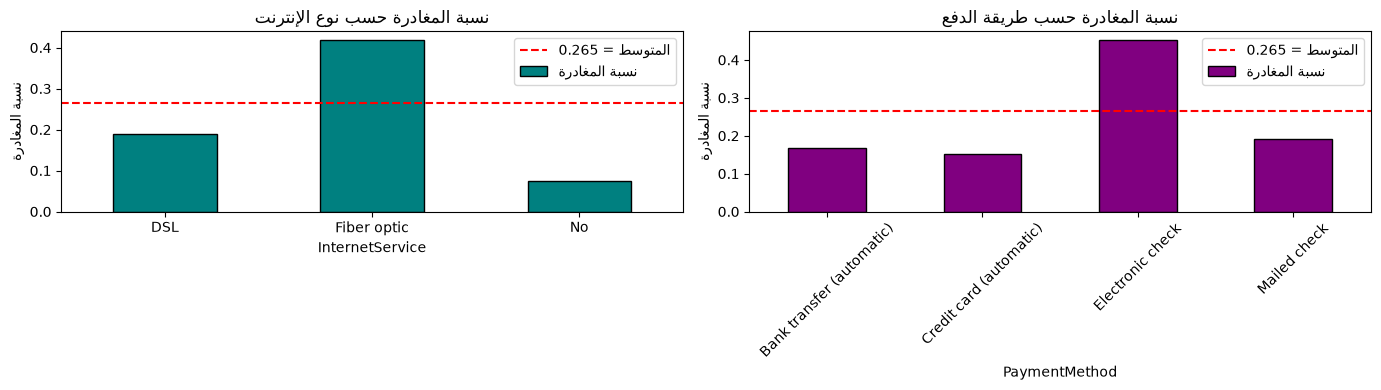

In [14]:
# الخلية 15: Churn حسب InternetService و PaymentMethod
# السؤال: هل نوع الإنترنت وطريقة الدفع يؤثران على المغادرة؟

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 1. InternetService
churn_by_internet = df.groupby("InternetService")["Churn"].agg(["count", "mean"]).round(3)
churn_by_internet.columns = ["عدد العملاء", "نسبة المغادرة"]
print("Churn حسب نوع الإنترنت:")
print(churn_by_internet)

churn_by_internet["نسبة المغادرة"].plot(kind="bar", ax=axes[0], color="teal", edgecolor="black")
axes[0].set_title("نسبة المغادرة حسب نوع الإنترنت")
axes[0].set_xlabel("InternetService")
axes[0].set_ylabel("نسبة المغادرة")
axes[0].axhline(df["Churn"].mean(), color="red", linestyle="--", label=f"المتوسط = {df['Churn'].mean():.3f}")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=0)

# 2. PaymentMethod
churn_by_payment = df.groupby("PaymentMethod")["Churn"].agg(["count", "mean"]).round(3)
churn_by_payment.columns = ["عدد العملاء", "نسبة المغادرة"]
print("\nChurn حسب طريقة الدفع:")
print(churn_by_payment)

churn_by_payment["نسبة المغادرة"].plot(kind="bar", ax=axes[1], color="purple", edgecolor="black")
axes[1].set_title("نسبة المغادرة حسب طريقة الدفع")
axes[1].set_xlabel("PaymentMethod")
axes[1].set_ylabel("نسبة المغادرة")
axes[1].axhline(df["Churn"].mean(), color="red", linestyle="--", label=f"المتوسط = {df['Churn'].mean():.3f}")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

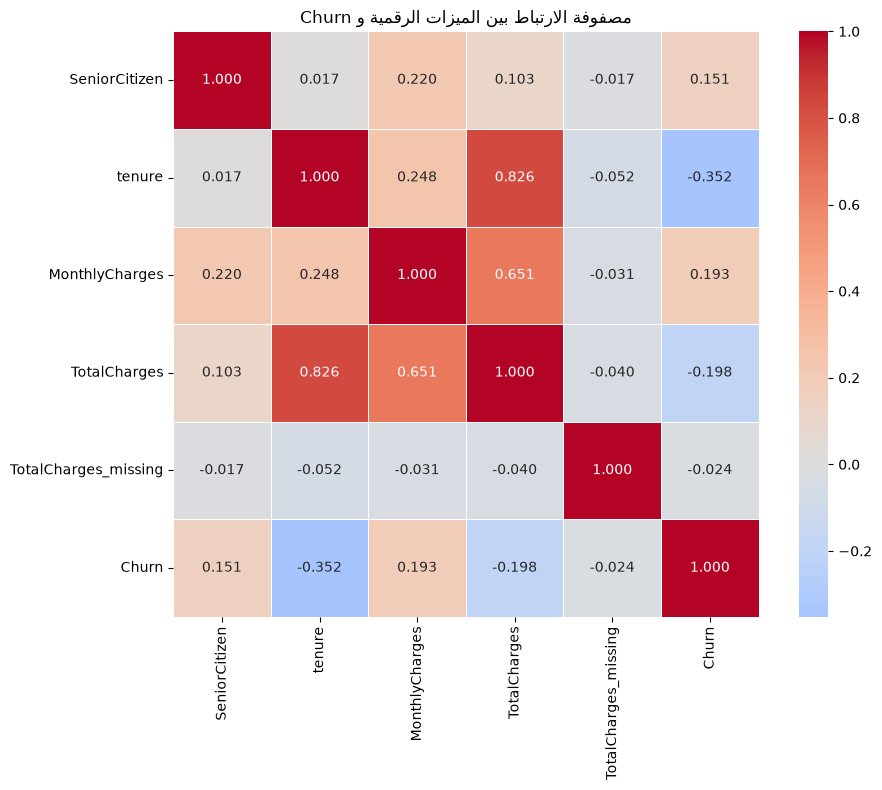

ارتباط كل ميزة رقمية مع Churn (مرتبة):
Churn                   1.000
MonthlyCharges          0.193
SeniorCitizen           0.151
TotalCharges_missing   -0.024
TotalCharges           -0.198
tenure                 -0.352
Name: Churn, dtype: float64


In [15]:
# الخلية 17: مصفوفة الارتباط (Correlation Matrix)
# نريد أن نرى أي الميزات الرقمية ترتبط بـ Churn أكثر

# نختار الأعمدة الرقمية فقط
numeric_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "TotalCharges_missing", "Churn"]

# نحسب مصفوفة الارتباط
corr_matrix = df[numeric_cols].corr()

# نرسمها
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("مصفوفة الارتباط بين الميزات الرقمية و Churn")
plt.tight_layout()
plt.show()

# نعرض ارتباط كل ميزة مع Churn (مرتبة)
print("ارتباط كل ميزة رقمية مع Churn (مرتبة):")
print(corr_matrix["Churn"].sort_values(ascending=False).round(3))

In [16]:
# الخلية 19: هندسة الميزات (Feature Engineering)
# الهدف: إنشاء ميزات جديدة بناءً على الرؤى من EDA

print("قبل هندسة الميزات:")
print(f"  عدد الأعمدة: {df.shape[1]}")

# 1. is_new_customer: عميل جديد (tenure < 6)
df["is_new_customer"] = (df["tenure"] < 6).astype(int)

# 2. is_fiber_optic: مشترك في Fiber optic
df["is_fiber_optic"] = (df["InternetService"] == "Fiber optic").astype(int)

# 3. is_electronic_check: يدفع بـ Electronic check
df["is_electronic_check"] = (df["PaymentMethod"] == "Electronic check").astype(int)

# 4. is_month_to_month: عقد شهري
df["is_month_to_month"] = (df["Contract"] == "Month-to-month").astype(int)

# 5. avg_monthly_charge: متوسط الفاتورة الشهرية (بديل عن TotalCharges)
# نضيف 1 لتجنب القسمة على صفر عند tenure=0
df["avg_monthly_charge"] = df["TotalCharges"] / (df["tenure"] + 1)

# 6. num_services: عدد الخدمات المشترك بها (فقط Yes)
service_cols = [
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]
# نحسب عدد "Yes" في هذه الأعمدة
df["num_services"] = df[service_cols].apply(lambda row: sum(row == "Yes"), axis=1)

print("\nبعد هندسة الميزات:")
print(f"  عدد الأعمدة: {df.shape[1]}")
print("\nالميزات الجديدة:")
print(df[["is_new_customer", "is_fiber_optic", "is_electronic_check",
          "is_month_to_month", "avg_monthly_charge", "num_services"]].head())

print("\nإحصائيات الميزات الجديدة:")
print(df[["is_new_customer", "is_fiber_optic", "is_electronic_check",
          "is_month_to_month", "avg_monthly_charge", "num_services"]].describe().round(2))

قبل هندسة الميزات:
  عدد الأعمدة: 21

بعد هندسة الميزات:
  عدد الأعمدة: 27

الميزات الجديدة:
   is_new_customer  is_fiber_optic  is_electronic_check  is_month_to_month  \
0                1               0                    1                  1   
1                0               0                    0                  0   
2                1               0                    0                  1   
3                0               0                    0                  0   
4                1               1                    1                  1   

   avg_monthly_charge  num_services  
0           14.925000             1  
1           53.985714             3  
2           36.050000             3  
3           40.016304             3  
4           50.550000             1  

إحصائيات الميزات الجديدة:
       is_new_customer  is_fiber_optic  is_electronic_check  \
count          7043.00         7043.00              7043.00   
mean              0.19            0.44                 0.

In [17]:
# الخلية 20: One-Hot Encoding للمتغيرات الفئوية

# 1. نحدد الأعمدة الفئوية (object) — بعد استبعاد Churn
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
print(f"الأعمدة الفئوية ({len(categorical_cols)}):")
print(categorical_cols)

# 2. نحدد الأعمدة الرقمية (للتأكد)
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
print(f"\nالأعمدة الرقمية ({len(numeric_cols)}):")
print(numeric_cols)

# 3. نطبق One-Hot Encoding
print(f"\nعدد الأعمدة قبل One-Hot: {df.shape[1]}")
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
print(f"عدد الأعمدة بعد One-Hot: {df_encoded.shape[1]}")

الأعمدة الفئوية (15):
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

الأعمدة الرقمية (12):
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TotalCharges_missing', 'is_new_customer', 'is_fiber_optic', 'is_electronic_check', 'is_month_to_month', 'avg_monthly_charge', 'num_services']

عدد الأعمدة قبل One-Hot: 27
عدد الأعمدة بعد One-Hot: 38


In [18]:
# الخلية 21: فصل الميزات (X) عن الهدف (y)
# الهدف: Churn
# الميزات: كل شيء آخر

# X = كل الأعمدة ما عدا Churn
X = df_encoded.drop(columns=["Churn"])

# y = Churn فقط
y = df_encoded["Churn"]

print(f"شكل X: {X.shape}")
print(f"شكل y: {y.shape}")
print(f"\nتوزيع y:")
print(y.value_counts(normalize=True).round(3))

شكل X: (7043, 37)
شكل y: (7043,)

توزيع y:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [19]:
# الخلية 22: معالجة Multicollinearity
# نحذف TotalCharges (ارتباط 0.826 مع tenure)
# نبقي avg_monthly_charge كبديل (لأنها تحمل معلومة إضافية)

print("قبل الحذف:")
print(f"  عدد أعمدة X: {X.shape[1]}")

# حذف TotalCharges
X = X.drop(columns=["TotalCharges"])

print("\nبعد الحذف:")
print(f"  عدد أعمدة X: {X.shape[1]}")

# التحقق: هل TotalCharges اختفى؟
print(f"\nهل TotalCharges موجود؟ {'TotalCharges' in X.columns}")
print(f"هل avg_monthly_charge موجود؟ {'avg_monthly_charge' in X.columns}")

قبل الحذف:
  عدد أعمدة X: 37

بعد الحذف:
  عدد أعمدة X: 36

هل TotalCharges موجود؟ False
هل avg_monthly_charge موجود؟ True


In [20]:
# الخلية 23: تقسيم البيانات إلى train/test
# 80% تدريب، 20% اختبار
# نستخدم stratify=y للحفاظ على نسبة الفئات في التقسيم

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # مهم جداً للبيانات غير المتوازنة
)

print(f"Train: X = {X_train.shape}, y = {y_train.shape}")
print(f"Test:  X = {X_test.shape}, y = {y_test.shape}")

print(f"\nنسبة Churn في Train: {y_train.mean():.3f}")
print(f"نسبة Churn في Test:  {y_test.mean():.3f}")
print(f"نسبة Churn في الكل:  {y.mean():.3f}")

Train: X = (5634, 36), y = (5634,)
Test:  X = (1409, 36), y = (1409,)

نسبة Churn في Train: 0.265
نسبة Churn في Test:  0.265
نسبة Churn في الكل:  0.265


In [21]:
# الخلية 24: Logistic Regression — Baseline
# نستخدم class_weight='balanced' لمعالجة عدم التوازن
# نحتاج StandardScaler لأن Logistic Regression حساسة للمقاييس

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)

# 1. تحجيم الميزات (StandardScaler)
# نتعلم من train فقط، ثم نطبق على test (لتجنب data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. تدريب النموذج
log_model = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
log_model.fit(X_train_scaled, y_train)

# 3. التوقع
y_pred_log = log_model.predict(X_test_scaled)
y_proba_log = log_model.predict_proba(X_test_scaled)[:, 1]

# 4. التقييم
print("=" * 60)
print("Logistic Regression — النتائج على Test")
print("=" * 60)
print(f"Accuracy : {accuracy_score(y_test, y_pred_log):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_log):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_log):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred_log):.4f}")
print(f"AUC      : {roc_auc_score(y_test, y_proba_log):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_log))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log, target_names=["No Churn", "Churn"]))

Logistic Regression — النتائج على Test
Accuracy : 0.7438
Precision: 0.5112
Recall   : 0.7914
F1-Score : 0.6212
AUC      : 0.8470

Confusion Matrix:
[[752 283]
 [ 78 296]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.73      0.81      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



In [22]:
# الخلية 25: Random Forest
# لا يحتاج تحجيم (الأشجار لا تتأثر بالمقاييس)

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print("=" * 60)
print("Random Forest — النتائج على Test")
print("=" * 60)
print(f"Accuracy : {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred_rf):.4f}")
print(f"AUC      : {roc_auc_score(y_test, y_proba_rf):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=["No Churn", "Churn"]))

Random Forest — النتائج على Test
Accuracy : 0.7580
Precision: 0.5307
Recall   : 0.7620
F1-Score : 0.6257
AUC      : 0.8408

Confusion Matrix:
[[783 252]
 [ 89 285]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.76      0.82      1035
       Churn       0.53      0.76      0.63       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



In [23]:
# الخلية 26: Gradient Boosting
# لا يدعم class_weight مباشرة في scikit-learn
# لكنه غالباً يعمل جيداً حتى بدونها

from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)
gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)
y_proba_gb = gb_model.predict_proba(X_test)[:, 1]

print("=" * 60)
print("Gradient Boosting — النتائج على Test")
print("=" * 60)
print(f"Accuracy : {accuracy_score(y_test, y_pred_gb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_gb):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_gb):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred_gb):.4f}")
print(f"AUC      : {roc_auc_score(y_test, y_proba_gb):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb, target_names=["No Churn", "Churn"]))

Gradient Boosting — النتائج على Test
Accuracy : 0.7956
Precision: 0.6327
Recall   : 0.5481
F1-Score : 0.5874
AUC      : 0.8387

Confusion Matrix:
[[916 119]
 [169 205]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.86      1035
       Churn       0.63      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [24]:
# الخلية 27: جدول مقارنة شامل
import pandas as pd

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "Gradient Boosting"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb)
    ],
    "F1": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb)
    ],
    "AUC": [
        roc_auc_score(y_test, y_proba_log),
        roc_auc_score(y_test, y_proba_rf),
        roc_auc_score(y_test, y_proba_gb)
    ]
}).round(4)

print(results.to_string(index=False))

# نبرز أفضل نموذج لكل مقياس
print("\n" + "=" * 60)
print("أفضل نموذج لكل مقياس:")
print("=" * 60)
for col in ["Accuracy", "Precision", "Recall", "F1", "AUC"]:
    best_idx = results[col].idxmax()
    print(f"{col:10s}: {results.loc[best_idx, 'Model']} ({results.loc[best_idx, col]:.4f})")

              Model  Accuracy  Precision  Recall     F1    AUC
Logistic Regression    0.7438     0.5112  0.7914 0.6212 0.8470
      Random Forest    0.7580     0.5307  0.7620 0.6257 0.8408
  Gradient Boosting    0.7956     0.6327  0.5481 0.5874 0.8387

أفضل نموذج لكل مقياس:
Accuracy  : Gradient Boosting (0.7956)
Precision : Gradient Boosting (0.6327)
Recall    : Logistic Regression (0.7914)
F1        : Random Forest (0.6257)
AUC       : Logistic Regression (0.8470)


In [25]:
# الخلية 28: ضبط Logistic Regression
# نبحث عن أفضل C (مقلوب التنظيم) و solver

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# مساحة البحث
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],  # C أصغر = تنظيم أقوى
    "solver": ["liblinear", "lbfgs"],
    "penalty": ["l2"]
}

# StratifiedKFold للحفاظ على نسب الفئات
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_log = GridSearchCV(
    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    param_grid,
    cv=cv,
    scoring="f1",  # نركز على F1 (توازن Precision/Recall)
    n_jobs=-1,
    verbose=1
)
grid_log.fit(X_train_scaled, y_train)

print("أفضل معاملات:", grid_log.best_params_)
print(f"أفضل CV F1: {grid_log.best_score_:.4f}")

# تقييم على Test
best_log = grid_log.best_estimator_
y_pred_best = best_log.predict(X_test_scaled)
y_proba_best = best_log.predict_proba(X_test_scaled)[:, 1]

print("\n" + "=" * 60)
print("Logistic Regression (Tuned) — على Test")
print("=" * 60)
print(f"Accuracy : {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred_best):.4f}")
print(f"AUC      : {roc_auc_score(y_test, y_proba_best):.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
أفضل معاملات: {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}
أفضل CV F1: 0.6341

Logistic Regression (Tuned) — على Test
Accuracy : 0.7452
Precision: 0.5130
Recall   : 0.7914
F1-Score : 0.6225
AUC      : 0.8461


C:\Users\hp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


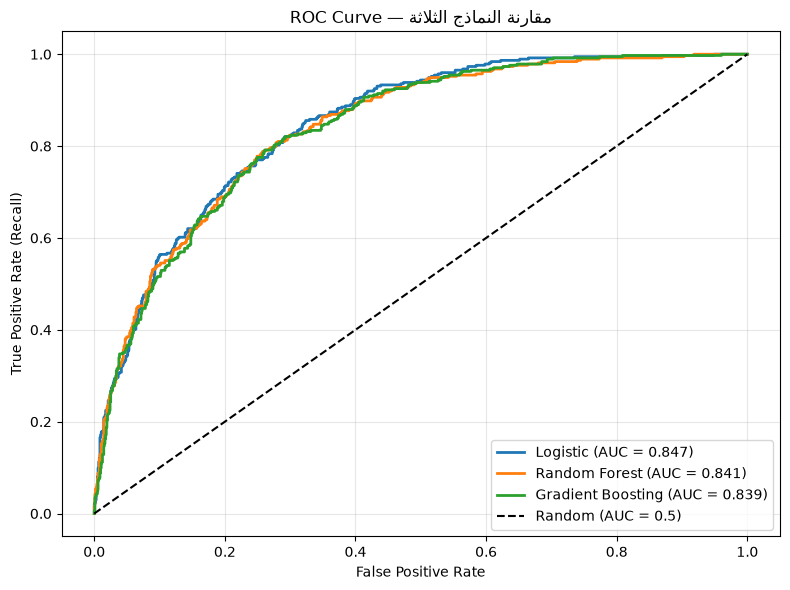

In [26]:
# الخلية 29: ROC Curve — مقارنة بصرية بين النماذج الثلاثة
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

# Logistic
fpr_log, tpr_log, _ = roc_curve(y_test, y_proba_log)
plt.plot(fpr_log, tpr_log, label=f"Logistic (AUC = {roc_auc_score(y_test, y_proba_log):.3f})", linewidth=2)

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_proba_rf):.3f})", linewidth=2)

# Gradient Boosting
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_proba_gb)
plt.plot(fpr_gb, tpr_gb, label=f"Gradient Boosting (AUC = {roc_auc_score(y_test, y_proba_gb):.3f})", linewidth=2)

# خط العشوائية
plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.5)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — مقارنة النماذج الثلاثة")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

أعلى 15 ميزة تأثيراً (بالقيمة المطلقة للمعامل):
                            Feature  Coefficient
                     MonthlyCharges    -0.802866
                 avg_monthly_charge    -0.659191
                     is_fiber_optic     0.511431
        InternetService_Fiber optic     0.511431
                             tenure    -0.469867
                  Contract_Two year    -0.392024
                  is_month_to_month     0.350956
                StreamingMovies_Yes     0.342372
                    StreamingTV_Yes     0.331349
                  MultipleLines_Yes     0.230609
                    is_new_customer     0.224090
                       num_services     0.205727
               TotalCharges_missing    -0.192258
               PaperlessBilling_Yes     0.166603
StreamingMovies_No internet service    -0.111915


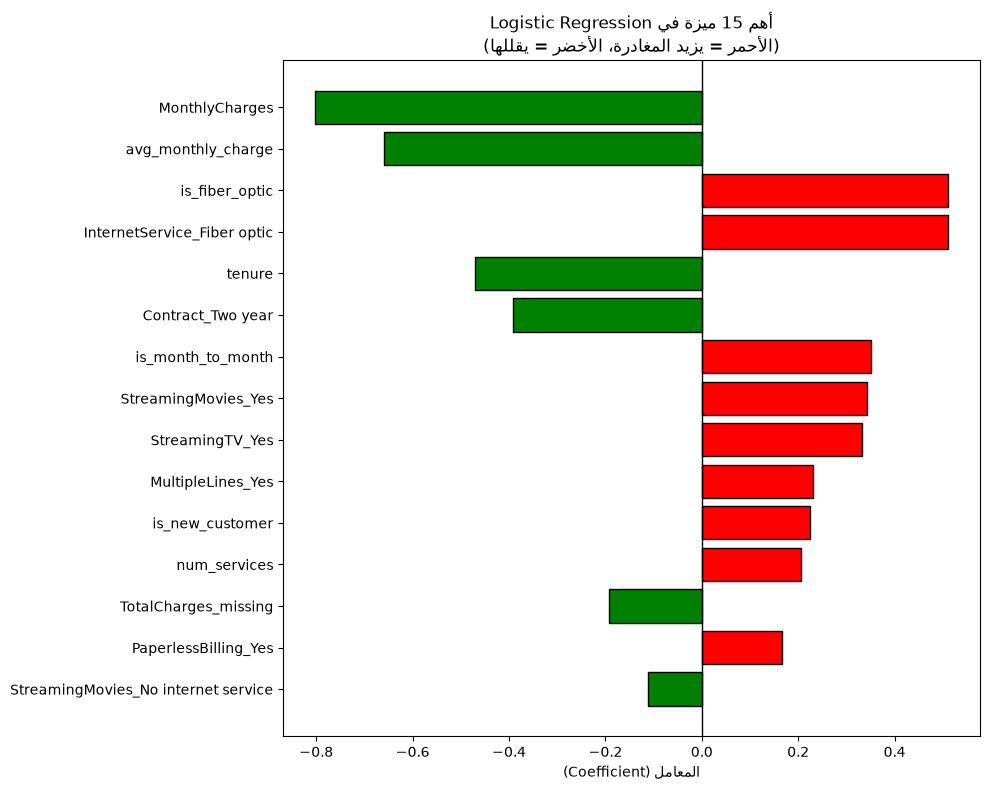

In [27]:
# الخلية 30: تفسير Logistic Regression
# المعاملات الموجبة = تزيد احتمالية المغادرة
# المعاملات السالبة = تقلل احتمالية المغادرة

# نستخدم النموذج المدرب في الخلية 24 (log_model)
coefs = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": log_model.coef_[0]
}).sort_values("Coefficient", key=abs, ascending=False)

# نعرض أعلى 15 ميزة تأثيراً
print("=" * 70)
print("أعلى 15 ميزة تأثيراً (بالقيمة المطلقة للمعامل):")
print("=" * 70)
print(coefs.head(15).to_string(index=False))

# نرسمها
plt.figure(figsize=(10, 8))
top_features = coefs.head(15).iloc[::-1]  # نعكس الترتيب للرسم
colors = ["red" if c > 0 else "green" for c in top_features["Coefficient"]]
plt.barh(top_features["Feature"], top_features["Coefficient"], color=colors, edgecolor="black")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("المعامل (Coefficient)")
plt.title("أهم 15 ميزة في Logistic Regression\n(الأحمر = يزيد المغادرة، الأخضر = يقللها)")
plt.tight_layout()
plt.show()

In [34]:
# الخلية 31: حفظ النموذج والـ Scaler
import pickle
import os

# إنشاء مجلد models إذا لم يكن موجوداً
os.makedirs("../models", exist_ok=True)

# حفظ النموذج
with open("../models/churn_logistic.pkl", "wb") as f:
    pickle.dump(log_model, f)

# حفظ الـ Scaler
with open("../models/scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

# حفظ أسماء الأعمدة (مهم جداً للنشر)
with open("../models/feature_names.pkl", "wb") as f:
    pickle.dump(X_train.columns.tolist(), f)

print("تم حفظ النموذج ✅")
print(f"  - models/churn_logistic.pkl")
print(f"  - models/scaler.pkl")
print(f"  - models/feature_names.pkl")

# التحقق: إعادة تحميل النموذج واختباره
with open("../models/churn_logistic.pkl", "rb") as f:
    loaded_model = pickle.load(f)

# اختبار سريع: هل التوقعات متطابقة؟
sample_pred = loaded_model.predict(X_test_scaled[:5])
print(f"\nاختبار سريع (أول 5 توقعات من النموذج المحمل): {sample_pred}")
print(f"التوقعات الأصلية: {log_model.predict(X_test_scaled[:5])}")

تم حفظ النموذج ✅
  - models/churn_logistic.pkl
  - models/scaler.pkl
  - models/feature_names.pkl

اختبار سريع (أول 5 توقعات من النموذج المحمل): [0 1 0 1 0]
التوقعات الأصلية: [0 1 0 1 0]
